# Spotify Song Clustering with Union-Find (Kruskal-style Hierarchical Clustering)

## Project overview
This notebook groups Spotify tracks by **how they sound**, using a hierarchical clustering method built on the **Union-Find (Disjoint Set Union)** data structure, implemented from scratch.

Unlike K-Means, the number of clusters is **not given in advance**. Every song starts as its own cluster, and the most similar groups are merged step by step, exactly as Kruskal's algorithm builds a minimum spanning tree. A size cap stops the merging from producing one giant cluster, and the cap is chosen by an explicit rule (see section 12).

## Pipeline

| Step | Section | What happens |
|---|---|---|
| 1 | 1-3 | Load the data, explore it, select the 9 audio features |
| 2 | 4-5 | Clean it: exact duplicates, missing and invalid values, repeated songs |
| 3 | 6-8 | Check correlations, standardise the features, save the preprocessed files |
| 4 | 9-10 | Union-Find from scratch, Euclidean distance |
| 5 | 11 | Build a sparse graph: each song is linked to its nearest neighbours |
| 6 | 12 | Kruskal merging with a size cap, and a stated rule for choosing the cap |
| 7 | 13-16 | Final clusters, evaluation, merge history, visualisation, cluster profiles |
| 8 | 17 | Sensitivity analysis of the choices |
| 9 | 18-19 | Save outputs, interpretation, limitations and complexity |

## Key concepts
- **Node**: one song. **Edge**: a link between two similar songs. **Edge weight**: the Euclidean distance between them (smaller = more similar).
- **Union-Find**: a data structure that tracks which songs are already in the same group, and merges groups, in near-constant time per operation.
- **Kruskal-style clustering**: process edges from shortest to longest; merge the two groups an edge connects, unless they are already one group.
- **Size cap `M`**: an edge is skipped when *both* of its groups already hold at least `M` songs. This keeps large groups from fusing into one cluster.

## Files
**Input:** `spotify-tracks-dataset-detailed.csv` (place it next to this notebook).

**Output:** `spotify_cleaned.csv`, `spotify_scaled_features.csv`, `spotify_metadata.csv`, `spotify_all_euclidean_distances.csv`, `spotify_merge_history.csv`, `spotify_clusters.csv`, `spotify_sensitivity.csv`.

Run the notebook top to bottom (**Kernel → Restart & Run All**). The whole run takes roughly 5-10 minutes, mostly in sections 12 and 17.

## 0. Setup and parameters
All tunable choices are defined once here, so each one is visible and can be changed in one place.

| Parameter | Value | Meaning |
|---|---|---|
| `SEED` | 0 | Makes every random step (samples, PCA, K-Means) reproducible |
| `K` | 20 | Neighbours per song used for the graph |
| `K_MAX` | 30 | Neighbours computed once; smaller `K` just uses the first columns |
| `THRESHOLD` | 2.0 | Longest edge (in standardised units) that is kept |
| `MAX_SHARE` | 0.40 | The largest cluster must hold less than this share of all songs |
| `SMALL` | 10 | Groups of this many songs or fewer are attached to the nearest larger cluster |
| `SIL_SAMPLE` | 10 000 | Silhouette is computed on a random sample, because it needs all pairwise distances |
| `DEDUP_IDENTICAL_AUDIO` | True | Keep one song when several have identical audio features (see section 5) |

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             normalized_mutual_info_score, pairwise_distances_argmin)
from scipy.cluster.hierarchy import linkage, dendrogram

RAW_FILE = 'spotify-tracks-dataset-detailed.csv'
SEED = 0
K, K_MAX = 20, 30
THRESHOLD = 2.0
MAX_SHARE = 0.40
SMALL = 10
SIL_SAMPLE = 10_000
DEDUP_IDENTICAL_AUDIO = True

if not Path(RAW_FILE).exists():
    raise FileNotFoundError(f'{RAW_FILE} not found. Put it in the same folder as this notebook.')

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

## 1. Load the data
The dataset is read into a DataFrame. We look at its size, column names and types before changing anything. `low_memory=False` makes pandas read each column's type consistently.

In [2]:
data = pd.read_csv(RAW_FILE, low_memory=False)
cleaning_log = [('raw file', len(data))]          # row count after every cleaning step
print('Raw shape:', data.shape)
display(data.head())
data.info()

Raw shape: (114000, 20)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  str    
 1   artists           113999 non-null  str    
 2   album_name        113999 non-null  str    
 3   track_name        113999 non-null  str    
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           114000 non-nu

## 2. Exploratory data analysis
Before cleaning, we check three things:
1. **Scales**: `describe()` shows that features live on very different scales (`tempo` is around 120, `danceability` is between 0 and 1). This is why standardisation is needed in section 7.
2. **Missing values**: which columns have gaps.
3. **Distributions**: histograms show the spread of each audio feature and any impossible values (for example `tempo = 0`).

In [3]:
display(data.describe().T.round(3))
print('Missing values per column:')
print(data.isnull().sum()[lambda s: s > 0])

,count,mean,std,min,25%,50%,75%,max
popularity,114000.0,33.239,22.305,0.000,17.000,35.000,50.000,100.000
duration_ms,114000.0,228029.153,107297.713,0.000,174066.000,212906.000,261506.000,5237295.000
danceability,114000.0,0.567,0.174,0.000,0.456,0.580,0.695,0.985
energy,114000.0,0.641,0.252,0.000,0.472,0.685,0.854,1.000
key,114000.0,5.309,3.560,0.000,2.000,5.000,8.000,11.000
loudness,114000.0,-8.259,5.029,-49.531,-10.013,-7.004,-5.003,4.532
mode,114000.0,0.638,0.481,0.000,0.000,1.000,1.000,1.000
speechiness,114000.0,0.085,0.106,0.000,0.036,0.049,0.084,0.965
acousticness,114000.0,0.315,0.333,0.000,0.017,0.169,0.598,0.996
instrumentalness,114000.0,0.156,0.310,0.000,0.000,0.000,0.049,1.000


Missing values per column:
artists       1
album_name    1
track_name    1
dtype: int64


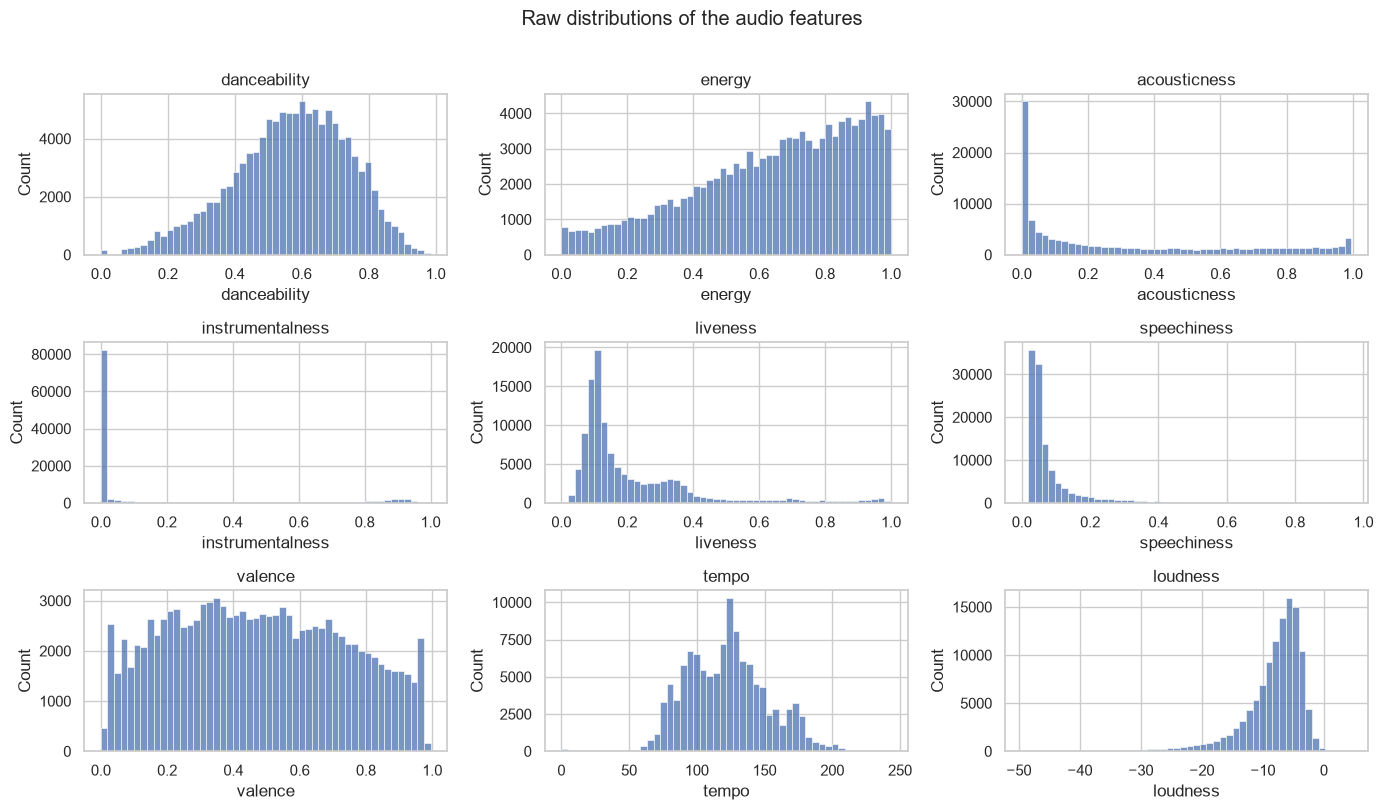

Rows with tempo = 0           : 157
Rows sharing a track_id        : 40900
Number of distinct track_ids   : 89741


In [4]:
audio_cols = ['danceability', 'energy', 'acousticness', 'instrumentalness', 'liveness',
              'speechiness', 'valence', 'tempo', 'loudness']
fig, axes = plt.subplots(3, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), audio_cols):
    sns.histplot(data[col], bins=50, ax=ax)
    ax.set_title(col)
plt.suptitle('Raw distributions of the audio features', y=1.01)
plt.tight_layout(); plt.show()

print('Rows with tempo = 0           :', int((data['tempo'] == 0).sum()))
print('Rows sharing a track_id        :', int(data['track_id'].duplicated(keep=False).sum()))
print('Number of distinct track_ids   :', data['track_id'].nunique())

## 3. Feature selection
Clustering should describe **sound**, so only the nine audio features are used as inputs:

`danceability, energy, acousticness, instrumentalness, liveness, speechiness, valence, tempo, loudness`

**Left out on purpose**
- `popularity` is listener behaviour, not a sound property. It is kept as metadata only.
- `key`, `mode`, `time_signature`: these are categorical or small-integer codes. Euclidean distance treats them as continuous numbers, which would be misleading.
- `duration_ms`, `explicit`, names and genre: descriptive attributes. Genre is **not** an input; it is used only afterwards to interpret and evaluate the clusters.

In [5]:
features = ['danceability', 'energy', 'acousticness', 'instrumentalness', 'liveness',
            'speechiness', 'valence', 'tempo', 'loudness']
# these seven are defined on the range [0, 1]; tempo and loudness are not bounded that way
bounded_features = ['danceability', 'energy', 'acousticness', 'instrumentalness',
                    'liveness', 'speechiness', 'valence']
missing_columns = [c for c in features if c not in data.columns]
assert not missing_columns, f'Required columns are missing: {missing_columns}'
print('Selected audio features:', features)

Selected audio features: ['danceability', 'energy', 'acousticness', 'instrumentalness', 'liveness', 'speechiness', 'valence', 'tempo', 'loudness']


## 4. Cleaning: exact duplicates, missing values and invalid values
Three problems are handled, in this order:

1. **Exact duplicate rows**: rows identical in *every* column are pure repetition and are removed.
2. **Missing values**: rows without `track_id`, `track_name`, `artists`, `popularity`, `track_genre` or any audio feature are removed. (The features are first converted to numbers and infinite values are treated as missing.)
3. **Invalid values**: a `[0, 1]` feature outside that range, or `tempo`, `time_signature` or `duration_ms` of zero or less, means Spotify's audio analysis failed for that track (silence, noise or a corrupted file). These rows would be wrong points in the feature space.

The order matters: cleaning happens **before** scaling, so bad values do not distort the scaler's mean and standard deviation.

In [6]:
before = len(data)
data = data.drop_duplicates().copy()
print('Exact duplicate rows removed:', before - len(data))
cleaning_log.append(('exact duplicate rows removed', len(data)))

data = data.dropna(subset=['track_id', 'track_name', 'artists'])
data[features] = data[features].apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=features + ['popularity', 'track_genre']).copy()
cleaning_log.append(('rows with missing values removed', len(data)))

valid = data[bounded_features].ge(0).all(axis=1) & data[bounded_features].le(1).all(axis=1)
valid &= (data['tempo'] > 0) & (data['time_signature'] > 0) & (data['duration_ms'] > 0)
print('Rows removed for invalid values:', int((~valid).sum()))
data = data.loc[valid].copy()
cleaning_log.append(('rows with invalid values removed', len(data)))

for col in ['popularity', 'duration_ms', 'key', 'mode', 'time_signature']:
    data[col] = data[col].astype(int)
print('Shape after cleaning:', data.shape)

Exact duplicate rows removed: 450
Rows removed for invalid values: 163
Shape after cleaning: (113386, 20)


## 5. Song-level duplicates
Exact duplicates are gone, but two further kinds of repetition remain:

- **The same `track_id` under several genres.** The dataset lists a song once per genre, so the rows differ only in `track_genre`. All of them have identical audio features.
- **Different `track_id`s with identical audio features.** Usually the same recording released on an album, a single and a compilation.

Both cases put several points at **distance 0** from each other. They add no information, they make dense areas look denser than they are, and they cause trivial zero-distance merges. So **each song is kept once**.

**No genre information is lost:** before a row is dropped, every genre it was listed under is collected into a new column `all_genres` (genres joined with `|`). `track_genre` keeps the genre of the first row, as the song's primary genre.

**A judgement call.** Removing rows with identical audio but *different track ids* is a choice: a few of them may be different songs that happen to share the same nine numbers. On this data about 90% of such groups have the same title, and most of the rest have the same artist with a slightly different title, such as a "(feat. ...)" version. To keep every `track_id` instead, set `DEDUP_IDENTICAL_AUDIO = False` in section 0. State whichever choice you make in the report.

In [7]:
print('Repeated track_ids      :', int(data['track_id'].duplicated().sum()))
print('Rows with identical audio:', int(data.duplicated(subset=features).sum()))

# 5a. one row per track_id, collecting all of its genres
all_genres = (data.groupby('track_id')['track_genre']
                  .agg(lambda s: '|'.join(sorted(set(s)))).rename('all_genres'))
data = (data.drop_duplicates(subset='track_id', keep='first')
            .merge(all_genres, on='track_id', how='left'))
cleaning_log.append(('one row per track_id', len(data)))

# 5b. one row per set of audio features; the genres of the dropped rows are merged into the kept row
if DEDUP_IDENTICAL_AUDIO:
    dup_mask = data.duplicated(subset=features, keep=False)
    merged = (data.loc[dup_mask].groupby(features, sort=False)['all_genres']
                  .transform(lambda s: '|'.join(sorted(set('|'.join(s).split('|'))))))
    data.loc[dup_mask, 'all_genres'] = merged
    data = data.drop_duplicates(subset=features, keep='first')
    cleaning_log.append(('one row per audio-feature vector', len(data)))
data = data.reset_index(drop=True)

assert not data['track_id'].duplicated().any()
if DEDUP_IDENTICAL_AUDIO:
    assert not data.duplicated(subset=features).any()
print('Final cleaned shape:', data.shape, '| primary genres:', data['track_genre'].nunique())

display(pd.DataFrame(cleaning_log, columns=['cleaning step', 'rows left'])
          .assign(removed=lambda d: (-d['rows left'].diff()).fillna(0).astype(int)))

Repeated track_ids      : 23808
Rows with identical audio: 30049
Final cleaned shape: (83337, 21) | primary genres: 113


,cleaning step,rows left,removed
0,raw file,114000,0
1,exact duplicate rows removed,113550,450
2,rows with missing values removed,113549,1
3,rows with invalid values removed,113386,163
4,one row per track_id,89578,23808
5,one row per audio-feature vector,83337,6241


## 6. Correlation check
Pearson correlation shows how strongly pairs of features move together (+1 together, 0 unrelated, -1 opposite). If two features are almost identical, they count twice in the Euclidean distance. Here `energy` and `loudness` correlate strongly, and `energy` and `acousticness` correlate negatively, but no pair is so strongly related that it should be removed, so all nine features are kept.

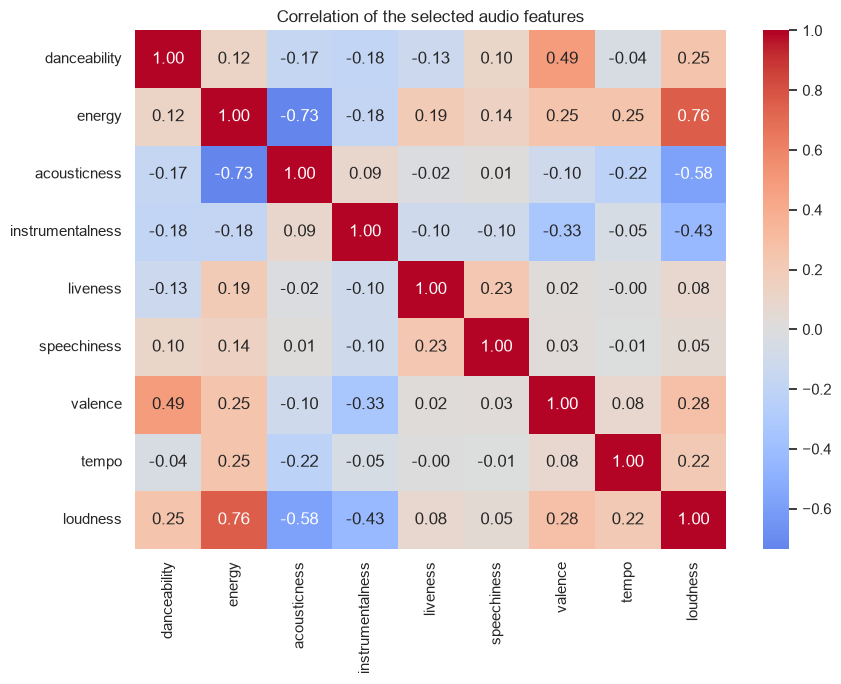

In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(data[features].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation of the selected audio features'); plt.tight_layout(); plt.show()

## 7. Standardisation
Euclidean distance adds up squared differences, so a feature with a large numeric range dominates. `tempo` (about 60-200) and `loudness` (about -40 to 0) would drown out the `[0, 1]` features. `StandardScaler` rescales every feature to **mean 0 and standard deviation 1** (a z-score), so all nine contribute fairly.

The scaler is fitted on the cleaned data only, and the result is checked for missing or infinite values. The row order of `scaled_features` is identical to `data`, which is essential: all graph edges refer to **row positions**.

,mean,std,min,max
danceability,0.0,1.0,-2.901,2.415
energy,0.0,1.0,-2.475,1.413
acousticness,0.0,1.0,-0.968,1.967
instrumentalness,-0.0,1.0,-0.550,2.493
liveness,0.0,1.0,-1.064,3.964
speechiness,0.0,1.0,-0.575,7.573
valence,0.0,1.0,-1.774,2.012
tempo,0.0,1.0,-3.108,4.078
loudness,-0.0,1.0,-7.280,2.502


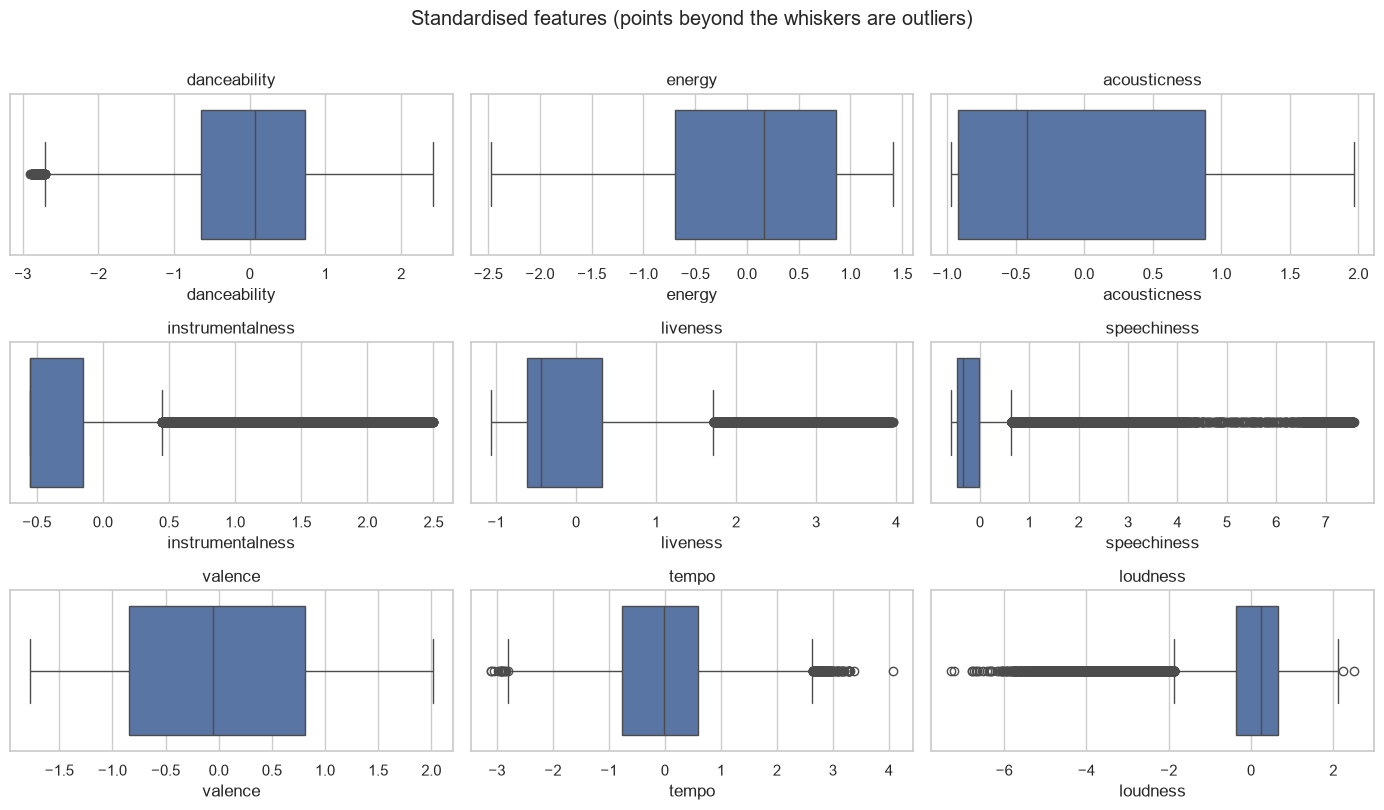

In [9]:
scaler = StandardScaler()
scaled_features = pd.DataFrame(scaler.fit_transform(data[features]), columns=features)
X = scaled_features.to_numpy(dtype=np.float32)
n = len(X)

assert len(data) == n
assert np.isfinite(X).all(), 'NaN or inf in scaled data'
display(scaled_features.describe().T[['mean', 'std', 'min', 'max']].round(3))

fig, axes = plt.subplots(3, 3, figsize=(14, 8))
for ax, f in zip(axes.ravel(), features):
    sns.boxplot(x=scaled_features[f], ax=ax); ax.set_title(f)
plt.suptitle('Standardised features (points beyond the whiskers are outliers)', y=1.01)
plt.tight_layout(); plt.show()

## 8. Save the preprocessing outputs
Three row-aligned files are written:
- `spotify_cleaned.csv`: the cleaned data with all columns,
- `spotify_scaled_features.csv`: the nine standardised features,
- `spotify_metadata.csv`: id, title, artists, genres and popularity, for looking songs up later.

A short summary and assertions confirm that the cleaning worked.

In [10]:
metadata_columns = ['track_id', 'track_name', 'artists', 'track_genre', 'all_genres', 'popularity']
data.to_csv('spotify_cleaned.csv', index=False)
scaled_features.to_csv('spotify_scaled_features.csv', index=False)
data[metadata_columns].to_csv('spotify_metadata.csv', index=False)

print('PREPROCESSING SUMMARY')
print('Songs                     :', n)
print('Features                  :', len(features))
print('Duplicate track_ids       :', int(data['track_id'].duplicated().sum()))
print('Duplicate feature vectors :', int(data.duplicated(subset=features).sum()))
print('Non-positive tempo        :', int((data['tempo'] <= 0).sum()))
print('Missing audio values      :', int(data[features].isna().sum().sum()))
assert data[features].isna().sum().sum() == 0 and (data['tempo'] > 0).all()

PREPROCESSING SUMMARY
Songs                     : 83337
Features                  : 9
Duplicate track_ids       : 0
Duplicate feature vectors : 0
Non-positive tempo        : 0
Missing audio values      : 0


## 9. Union-Find (Disjoint Set Union) from scratch
Union-Find keeps track of which songs belong to the same group. Every song starts alone; `union` merges two groups; `find` tells which group a song is in.

Two optimisations make each operation almost constant time (inverse-Ackermann, practically below 5):
- **Path halving** (in `find`): while walking up to the root, each node is pointed at its grandparent, which flattens the tree for future searches.
- **Union by size** (in `union`): the smaller tree is attached below the larger one, so trees stay shallow.

| Method | Purpose |
|---|---|
| `find(x)` | root (representative) of the group that contains `x` |
| `union(a, b)` | merge the groups of `a` and `b`; returns `False` if they were already together |
| `connected(a, b)` | whether two songs are in the same group |
| `component_size(x)` | number of songs in the group of `x` |

A small test checks the implementation before it is used on the real data.

In [11]:
class UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))   # parent[i] = parent of i (a root points to itself)
        self.size = [1] * n            # size[r] = number of songs in the tree rooted at r
        self.components = n            # current number of groups

    def find(self, x):
        # return the root of x, halving the path on the way up
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x

    def union(self, a, b):
        # merge the groups of a and b; return False if they were already merged
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False
        if self.size[ra] < self.size[rb]:      # attach the smaller tree under the larger one
            ra, rb = rb, ra
        self.parent[rb] = ra
        self.size[ra] += self.size[rb]
        self.components -= 1
        return True

    def connected(self, a, b):
        return self.find(a) == self.find(b)

    def component_size(self, x):
        return self.size[self.find(x)]


# sanity checks on a small example
t = UnionFind(6)
assert t.union(0, 1) and t.union(1, 2) and not t.union(0, 2)
assert t.connected(0, 2) and not t.connected(0, 4)
assert t.component_size(1) == 3 and t.components == 4
t.union(3, 4); t.union(4, 5); t.union(2, 3)
assert t.component_size(5) == 6 and t.components == 1
print('Union-Find tests passed.')

Union-Find tests passed.


## 10. Euclidean distance
Each song is a point in nine dimensions. The distance between two songs is

$$d(a, b) = \sqrt{\sum_{i=1}^{9} (a_i - b_i)^2}$$

A small distance means similar sound. The next cell implements the formula and checks it against scikit-learn's result.

In [12]:
def euclidean_distance(a, b):
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    return np.sqrt(np.sum((a - b) ** 2))

d01 = euclidean_distance(X[0], X[1])
d_check = NearestNeighbors(n_neighbors=2).fit(X[:2]).kneighbors(X[:1])[0][0, 1]
assert abs(d01 - d_check) < 1e-4
print(f'Distance between the first two songs: {d01:.4f}')
display(pd.DataFrame({'song': data.loc[:1, 'track_name'], 'artist': data.loc[:1, 'artists']}))

Distance between the first two songs: 4.4086


,song,artist
0,Comedy,Gen Hoshino
1,Ghost - Acoustic,Ben Woodward


## 11. Candidate edges: a symmetric k-nearest-neighbour graph
With 83 000 songs there are about 3.5 billion pairs, so storing all distances is impossible. Instead each song keeps only its **`K` nearest neighbours**, which gives a sparse graph that still holds the short edges Kruskal's algorithm needs first.

Design choices:
- **Symmetric**: an edge is kept if *either* song lists the other as a neighbour, and every pair is stored once as `(small index, large index)`.
- **Distance threshold**: edges longer than `THRESHOLD` link songs that are not really similar and are dropped.
- **Computed once for `K_MAX = 30`**: a smaller `K` just uses the first `K` columns, which the sensitivity analysis (section 17) relies on.
- Edges are sorted by distance, ready for Kruskal.

In [13]:
nn = NearestNeighbors(n_neighbors=K_MAX + 1, metric='euclidean', n_jobs=-1).fit(X)
dist_all, idx_all = nn.kneighbors(X)          # column 0 is the song itself

def build_edges(K, threshold):
    src = np.repeat(np.arange(n), K)
    dst = idx_all[:, 1:K + 1].ravel()
    w = dist_all[:, 1:K + 1].ravel()
    keep = src != dst
    if threshold is not None:
        keep &= (w <= threshold)
    e = pd.DataFrame({'track_i_index': np.minimum(src[keep], dst[keep]),
                      'track_j_index': np.maximum(src[keep], dst[keep]),
                      'euclidean_distance': w[keep]})
    return (e.drop_duplicates(['track_i_index', 'track_j_index'])
             .sort_values('euclidean_distance', kind='stable').reset_index(drop=True))

edges = build_edges(K, THRESHOLD)
assert edges[['track_i_index', 'track_j_index']].to_numpy().max() < n
edges.to_csv('spotify_all_euclidean_distances.csv', index=False)

eu = edges['track_i_index'].tolist()
ev = edges['track_j_index'].tolist()

has_edge = np.zeros(n, bool)
has_edge[edges['track_i_index']] = True; has_edge[edges['track_j_index']] = True
print(f'Edges: {len(edges):,} | songs with no edge within {THRESHOLD}: {(~has_edge).sum()}')
print('Edge distance quantiles:', edges['euclidean_distance'].quantile([.5, .9, .99]).round(3).to_dict())

Edges: 1,138,212 | songs with no edge within 2.0: 38
Edge distance quantiles: {0.5: 0.715, 0.9: 1.144, 0.99: 1.667}


### Why `THRESHOLD = 2.0`
The table below uses the simplest clustering, plain **connected components** of the graph (no size cap), for several thresholds. It shows how many songs are left without any neighbour, and how much of the data one group swallows.

- A **small** threshold leaves many songs isolated (singletons).
- A **large** threshold lets almost every song chain into one huge group.

`2.0` is a compromise: only a few songs (under 0.1%) stay isolated, and the kept edges are the short ones (99% of edges are under 1.7). But the table also shows that **no threshold alone gives useful clusters**, because at 2.0 nearly all songs are still connected. That is exactly why section 12 adds a size cap.

,threshold,edges,components,singleton songs,largest component %
0,1.0,932644,2947,2620,95.00
1,1.5,1112768,298,263,99.58
2,1.75,1131000,106,94,99.85
3,2.0,1138212,44,38,99.94
4,2.25,1141966,25,20,99.96
5,2.5,1143695,9,8,99.99
6,none,1145214,1,0,100.00


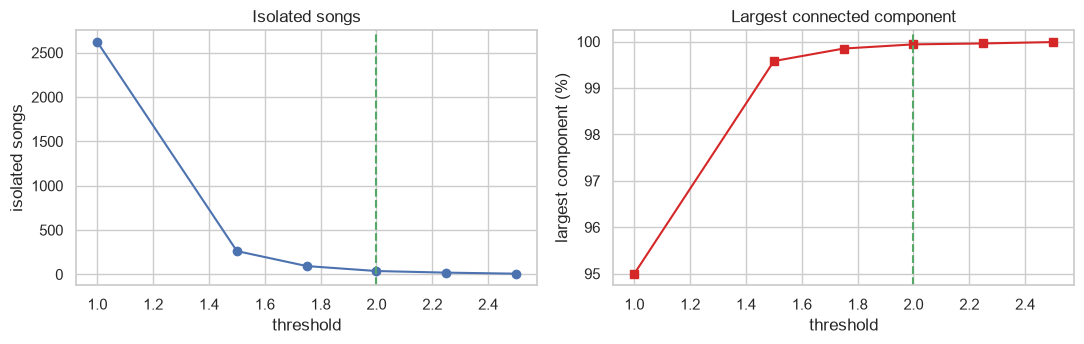

In [14]:
all_edges = build_edges(K, None)       # every symmetric kNN edge, sorted by distance
d_all = all_edges['euclidean_distance'].to_numpy()
a_all, b_all = all_edges['track_i_index'].to_numpy(), all_edges['track_j_index'].to_numpy()

rows = []
for thr in (1.0, 1.5, 1.75, 2.0, 2.25, 2.5, None):
    m = np.ones(len(d_all), bool) if thr is None else d_all <= thr
    uf_t = UnionFind(n)
    for a, b in zip(a_all[m].tolist(), b_all[m].tolist()):
        uf_t.union(a, b)
    sz = np.bincount(np.unique([uf_t.find(i) for i in range(n)], return_inverse=True)[1])
    rows.append({'threshold': 'none' if thr is None else thr, 'edges': int(m.sum()),
                 'components': uf_t.components, 'singleton songs': int((sz == 1).sum()),
                 'largest component %': round(100 * sz.max() / n, 2)})
threshold_table = pd.DataFrame(rows)
display(threshold_table)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
t_plot = threshold_table[threshold_table['threshold'] != 'none']
ax[0].plot(t_plot['threshold'], t_plot['singleton songs'], 'o-'); ax[0].axvline(THRESHOLD, c='g', ls='--')
ax[0].set_xlabel('threshold'); ax[0].set_ylabel('isolated songs'); ax[0].set_title('Isolated songs')
ax[1].plot(t_plot['threshold'], t_plot['largest component %'], 's-', c='tab:red'); ax[1].axvline(THRESHOLD, c='g', ls='--')
ax[1].set_xlabel('threshold'); ax[1].set_ylabel('largest component (%)'); ax[1].set_title('Largest connected component')
plt.tight_layout(); plt.show()

## 12. Kruskal merging with a size cap, and a stated rule for choosing `M`
**Algorithm.** Take the edges from shortest to longest. For each edge, find the groups of its two songs. If they are already the same group, skip it. Otherwise merge them, **unless both groups already hold at least `M` songs**. That last rule is the size cap: small groups keep growing, but two large groups are never fused, so the process cannot collapse into one giant cluster.

**Rule for `M`.** The number of clusters is not chosen by hand. A grid of `M` values is tried, and the chosen `M` is the one with the **best silhouette score, subject to the largest cluster holding under 40% of the songs**. If no `M` satisfies the limit, the most balanced result is taken instead.

**Tiny groups.** After merging, groups with `SMALL` songs or fewer are attached to the cluster with the nearest centroid, so that no cluster is made up of a handful of isolated songs.

,M,clusters,largest_cluster_%,silhouette
0,20,201,3.761,-0.154
1,30,94,7.870,-0.126
2,45,54,13.343,-0.084
3,68,27,16.552,-0.031
4,101,14,19.119,0.034
5,152,10,24.677,0.068
6,228,7,34.898,0.080
7,342,5,59.575,0.176
8,513,5,59.575,0.176
9,769,4,78.952,0.184


Chosen M = 228


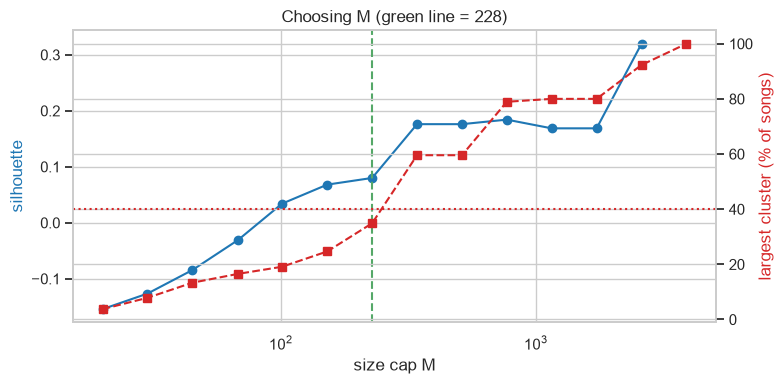

In [15]:
M_GRID = [int(round(20 * 1.5 ** i)) for i in range(14)]

def kruskal_capped(M, eu, ev):
    uf = UnionFind(n)
    find, size = uf.find, uf.size
    for a, b in zip(eu, ev):
        ra, rb = find(a), find(b)
        if ra != rb and (size[ra] < M or size[rb] < M):
            uf.union(ra, rb)
    return uf

def finalize(uf):
    # final labels; groups of SMALL songs or fewer join the nearest larger cluster
    labels = np.unique([uf.find(i) for i in range(n)], return_inverse=True)[1]
    sizes = np.bincount(labels)
    small, big = np.where(sizes <= SMALL)[0], np.where(sizes > SMALL)[0]
    if len(small) and len(big):
        centres = pd.DataFrame(X).groupby(labels).mean().to_numpy()
        remap = np.arange(len(sizes))
        remap[small] = big[pairwise_distances_argmin(centres[small], centres[big])]
        labels = np.unique(remap[labels], return_inverse=True)[1]
    return labels, len(small), int(sizes[small].sum())

def select_M(eu, ev, keep_runs=False):
    rows, runs = [], {}
    for m in M_GRID:
        uf = kruskal_capped(m, eu, ev)
        lab, _, _ = finalize(uf)
        k = int(lab.max()) + 1
        rows.append({'M': m, 'clusters': k,
                     'largest_cluster_%': 100 * np.bincount(lab).max() / n,
                     'silhouette': silhouette_score(X, lab, sample_size=SIL_SAMPLE, random_state=SEED) if k > 1 else np.nan})
        if keep_runs:
            runs[m] = uf
    table = pd.DataFrame(rows)
    ok = table[(table['clusters'] > 1) & (table['largest_cluster_%'] < 100 * MAX_SHARE)]
    if len(ok):
        chosen = int(ok.loc[ok['silhouette'].idxmax(), 'M'])
    else:                                    # nothing satisfies the limit: take the most balanced result
        chosen = int(table.loc[table['largest_cluster_%'].idxmin(), 'M'])
    return table, chosen, runs

M_table, M, runs = select_M(eu, ev, keep_runs=True)
display(M_table.round(3))
print(f'Chosen M = {M}')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(M_table['M'], M_table['silhouette'], 'o-', c='tab:blue')
ax.set_xscale('log'); ax.set_xlabel('size cap M'); ax.set_ylabel('silhouette', color='tab:blue')
ax2 = ax.twinx()
ax2.plot(M_table['M'], M_table['largest_cluster_%'], 's--', c='tab:red')
ax2.axhline(100 * MAX_SHARE, c='tab:red', ls=':'); ax2.set_ylabel('largest cluster (% of songs)', color='tab:red')
ax.axvline(M, c='g', ls='--'); ax.set_title(f'Choosing M (green line = {M})')
plt.tight_layout(); plt.show()

### Reading the table
- **Small `M`** (20-45) gives dozens or hundreds of small clusters and a negative silhouette: the data is cut into pieces that are too fine.
- **Large `M`** (769 and above) gives 4 or fewer clusters, with one cluster holding 79-100% of the songs.
- **The highest silhouette is not the best choice.** `M = 2595` scores 0.320, but it gives only 2 clusters and one holds 92% of the songs. Silhouette alone rewards this lopsided split, which is why the rule requires the largest cluster to stay under 40%.
- Among the values that pass that limit, **`M = 228` has the best silhouette (0.080)** and gives 7 reasonably balanced clusters.

### What happens without the size cap?
For comparison, the same merging is run with **no cap** (`M = n`). This is the plain connected-components result from section 11. Its few isolated songs are attached to the nearest cluster, and everything else has already chained together, so the result is **a single cluster holding 100% of the songs**. That is why the cap is necessary.

In [16]:
uf_nocap = kruskal_capped(n, eu, ev)
lab_nocap, _, _ = finalize(uf_nocap)
sz_nocap = np.bincount(lab_nocap)
print(f'Without a cap: {len(sz_nocap)} clusters, largest holds {100 * sz_nocap.max() / n:.1f}% of all songs')
print(f'With M = {M}   : {int(finalize(runs[M])[0].max()) + 1} clusters, '
      f'largest holds {100 * np.bincount(finalize(runs[M])[0]).max() / n:.1f}% of all songs')

Without a cap: 1 clusters, largest holds 100.0% of all songs
With M = 228   : 7 clusters, largest holds 34.9% of all songs


## 13. Final clusters and evaluation
The labels for the chosen `M` are attached to the data. Quality is measured with three **internal** scores, plus one **external** score that uses genre:

| Score | Better when | Meaning |
|---|---|---|
| Silhouette (-1 to 1) | higher | how much closer a song is to its own cluster than to the next one |
| Davies-Bouldin | lower | average similarity of each cluster to its most similar cluster |
| NMI vs genre (0 to 1) | higher | how much the clusters agree with genre; genre was *not* used for clustering |

**K-Means** with the same number of clusters is shown as a reference, not as a competitor to beat. It optimises a different objective directly.

In [17]:
uf = runs[M]
labels, n_tiny, tiny_songs = finalize(uf)
print(f'Tiny groups attached to a larger cluster: {n_tiny} ({tiny_songs} songs)')

data['cluster'] = labels
sizes = np.bincount(labels)
print(f'Clusters: {len(sizes)} | sizes: {sorted(sizes.tolist(), reverse=True)}')

def report(name, lab):
    print(f'{name:<24} k={len(set(lab)):<3} silhouette={silhouette_score(X, lab, sample_size=SIL_SAMPLE, random_state=SEED):.3f}  '
          f'Davies-Bouldin={davies_bouldin_score(X, lab):.3f}  NMI vs genre={normalized_mutual_info_score(data["track_genre"], lab):.3f}')

report('Union-Find (Kruskal, M)', labels)
report('K-Means (reference)', KMeans(len(sizes), n_init=3, random_state=SEED).fit_predict(X))

Tiny groups attached to a larger cluster: 43 (51 songs)
Clusters: 7 | sizes: [29083, 20566, 14344, 10248, 6399, 1809, 888]
Union-Find (Kruskal, M)  k=7   silhouette=0.080  Davies-Bouldin=2.151  NMI vs genre=0.147
K-Means (reference)      k=7   silhouette=0.197  Davies-Bouldin=1.387  NMI vs genre=0.178


## 14. Merge history
Every merge performed is recorded as one row, in the style of a dendrogram linkage table:

| Column | Meaning |
|---|---|
| `Cluster A`, `Cluster B` | ids of the two groups merged (a song is its row index `0..n-1`; each new group gets the next id `n, n+1, ...`) |
| `Distance` | length of the edge that caused the merge |
| `New Size` | number of songs in the new group |

The same rules as section 12 are used, so replaying the history must reproduce the same number of groups. An assertion checks this. (The final attachment of tiny groups is *not* a Kruskal merge, so it is not part of the history.)

In [18]:
hist_uf = UnionFind(n)
node_id = np.arange(n)          # id of the current cluster node at each root (n, n+1, ... for merged nodes)
rows = []
for a, b, d in zip(eu, ev, edges['euclidean_distance'].to_numpy()):
    ra, rb = hist_uf.find(a), hist_uf.find(b)
    if ra != rb and not (hist_uf.size[ra] >= M and hist_uf.size[rb] >= M):
        left, right = node_id[ra], node_id[rb]
        new_size = hist_uf.size[ra] + hist_uf.size[rb]
        hist_uf.union(a, b)
        node_id[hist_uf.find(a)] = n + len(rows)
        rows.append([left, right, float(d), new_size])

merge_history = pd.DataFrame(rows, columns=['Cluster A', 'Cluster B', 'Distance', 'New Size'])
merge_history.to_csv('spotify_merge_history.csv', index=False)

assert merge_history['Distance'].is_monotonic_increasing          # Kruskal order
assert hist_uf.components == runs[M].components                   # replay matches section 12
assert len(merge_history) == n - runs[M].components
print('Recorded merges:', len(merge_history), '| zero-distance merges:', int((merge_history['Distance'] == 0).sum()))
display(merge_history.head()); display(merge_history.tail())

Recorded merges: 83287 | zero-distance merges: 0


,Cluster A,Cluster B,Distance,New Size
0,2782,2880,0.000015,2
1,25983,63929,0.000015,2
2,25635,25872,0.000034,2
3,52746,52905,0.000034,2
4,42222,53509,0.000034,2


,Cluster A,Cluster B,Distance,New Size
83282,166616,76605,1.976642,29083
83283,166618,47021,1.980520,6378
83284,166588,43999,1.983259,869
83285,76255,166620,1.995807,6379
83286,166621,16382,1.998965,870


## 15. Visualisation
- **Left:** the length of each merge, in order. It only increases, because edges are processed shortest first.
- **Right:** the size of the largest cluster so far. It shows the size cap at work, as growth flattens near `M`.
- **PCA scatter:** the nine-dimensional songs projected onto the two directions of greatest variance and coloured by cluster. Two dimensions cannot show everything, so clusters can overlap in the picture even when they differ in other dimensions.

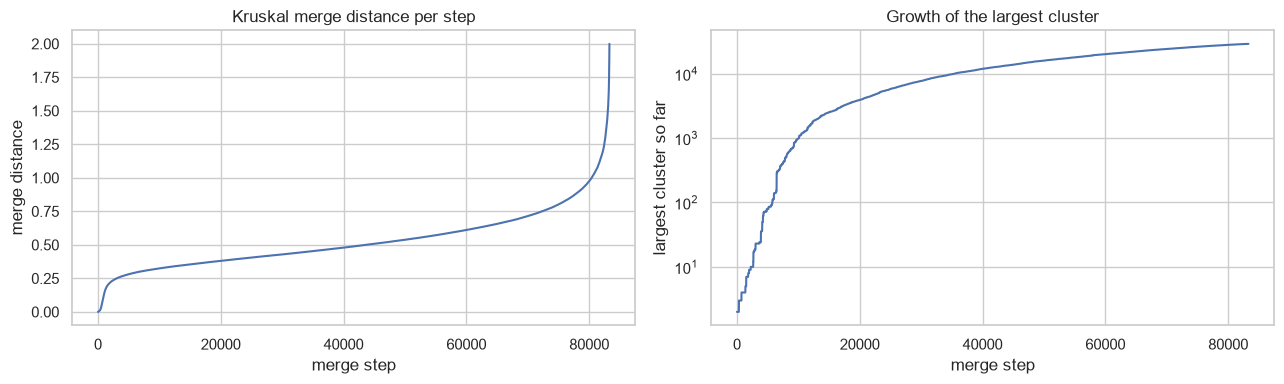

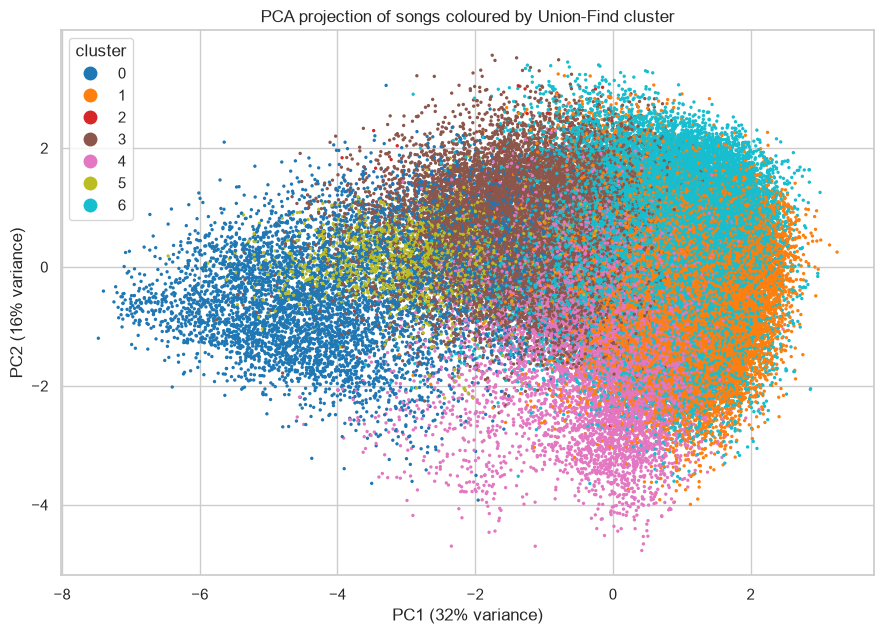

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(merge_history['Distance'].to_numpy())
ax[0].set_xlabel('merge step'); ax[0].set_ylabel('merge distance'); ax[0].set_title('Kruskal merge distance per step')
ax[1].plot(merge_history['New Size'].cummax().to_numpy())
ax[1].set_yscale('log'); ax[1].set_xlabel('merge step'); ax[1].set_ylabel('largest cluster so far'); ax[1].set_title('Growth of the largest cluster')
plt.tight_layout(); plt.show()

pca = PCA(2, random_state=SEED)
Z = pca.fit_transform(X)
plt.figure(figsize=(9, 6.5))
sc = plt.scatter(Z[:, 0], Z[:, 1], c=labels, s=2, cmap='tab10')
plt.legend(*sc.legend_elements(), title='cluster', markerscale=1.5, loc='best')
plt.xlabel(f'PC1 ({100 * pca.explained_variance_ratio_[0]:.0f}% variance)')
plt.ylabel(f'PC2 ({100 * pca.explained_variance_ratio_[1]:.0f}% variance)')
plt.title('PCA projection of songs coloured by Union-Find cluster')
plt.tight_layout(); plt.show()

## 16. What do the clusters mean?
- **Profile heatmap:** the mean z-score of each feature per cluster. Red means above average, blue below average, so each row describes the typical sound of the cluster (for example high `energy` and `loudness`, or high `acousticness`).
- **Size and top genres:** how large each cluster is and which genres dominate it. Genres were not used for clustering, so a dominant genre is a sign that sound and genre are related.
- **Dendrogram:** how the final clusters relate to each other (single linkage on the cluster centroids).

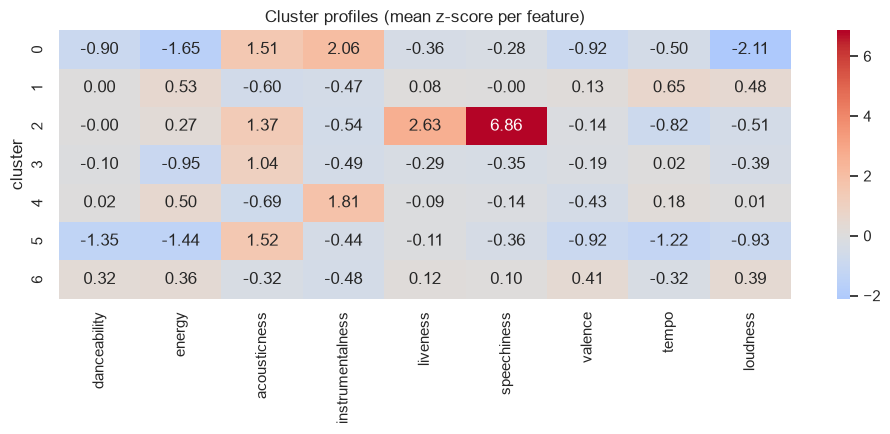

,size,top genres
cluster,,
0,6399,"new-age (11%), ambient (10%), study (9%)"
1,20566,"j-idol (3%), hardstyle (2%), happy (2%)"
2,888,"comedy (90%), kids (1%), show-tunes (1%)"
3,14344,"honky-tonk (5%), cantopop (5%), tango (4%)"
4,10248,"detroit-techno (7%), minimal-techno (7%), grin..."
5,1809,"opera (16%), romance (12%), show-tunes (8%)"
6,29083,"salsa (2%), dancehall (2%), kids (2%)"


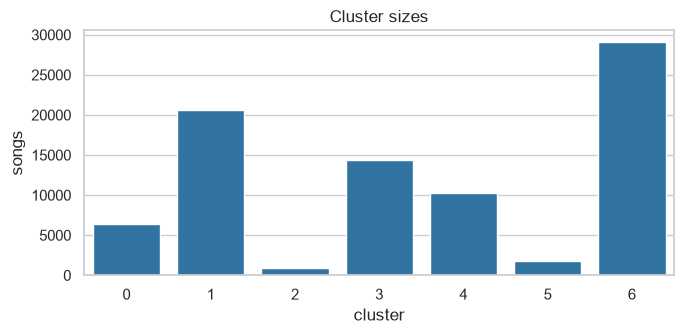

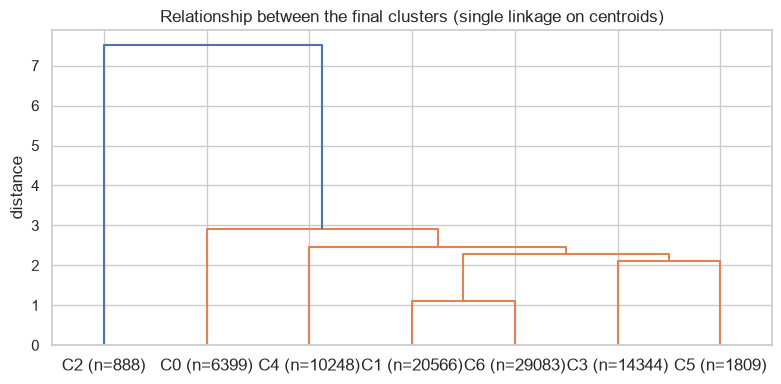

In [20]:
profile = scaled_features.groupby(labels).mean()
profile.index.name = 'cluster'
plt.figure(figsize=(10, 4.5))
sns.heatmap(profile, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Cluster profiles (mean z-score per feature)'); plt.tight_layout(); plt.show()

summary = data.groupby('cluster').agg(size=('track_id', 'size'))
summary['top genres'] = data.groupby('cluster')['track_genre'].agg(
    lambda s: ', '.join(f'{g} ({v * 100:.0f}%)' for g, v in s.value_counts(normalize=True).head(3).items()))
display(summary)

plt.figure(figsize=(7, 3.5))
sns.barplot(x=summary.index, y=summary['size'], color='tab:blue')
plt.xlabel('cluster'); plt.ylabel('songs'); plt.title('Cluster sizes'); plt.tight_layout(); plt.show()

cent = profile.to_numpy()
plt.figure(figsize=(8, 4))
dendrogram(linkage(cent, method='single'), labels=[f'C{c} (n={s})' for c, s in zip(profile.index, sizes)])
plt.title('Relationship between the final clusters (single linkage on centroids)')
plt.ylabel('distance'); plt.tight_layout(); plt.show()

## 17. Sensitivity of the choices
A result that exists for only one lucky setting is not trustworthy. The complete procedure, including the rule for `M`, is re-run for different neighbour counts `K` and thresholds (`none` keeps every kNN edge). If the number of clusters and the scores stay in a similar range, the result does not hinge on one choice.

This cell is the slowest one in the notebook.

In [21]:
rows = []
for K_s in (10, 20, 30):
    for thr_s in (1.5, 2.0, None):
        e = build_edges(K_s, thr_s)
        eu_s, ev_s = e['track_i_index'].tolist(), e['track_j_index'].tolist()
        _, M_s, _ = select_M(eu_s, ev_s)
        lab_s, _, _ = finalize(kruskal_capped(M_s, eu_s, ev_s))
        linked = np.zeros(n, bool); linked[e['track_i_index']] = True; linked[e['track_j_index']] = True
        rows.append({'K': K_s, 'threshold': 'none' if thr_s is None else thr_s, 'edges': len(e),
                     'songs without edge': int((~linked).sum()), 'chosen M': M_s,
                     'clusters': int(lab_s.max()) + 1,
                     'largest cluster %': round(100 * np.bincount(lab_s).max() / n, 1),
                     'silhouette': round(silhouette_score(X, lab_s, sample_size=SIL_SAMPLE, random_state=SEED), 3),
                     'Davies-Bouldin': round(davies_bouldin_score(X, lab_s), 3),
                     'NMI vs genre': round(normalized_mutual_info_score(data['track_genre'], lab_s), 3)})
sensitivity = pd.DataFrame(rows)
sensitivity.to_csv('spotify_sensitivity.csv', index=False)
display(sensitivity)

,K,threshold,edges,songs without edge,chosen M,clusters,largest cluster %,silhouette,Davies-Bouldin,NMI vs genre
0,10,1.5,566936,263,228,7,34.8,0.081,2.151,0.147
1,10,2.0,574970,38,228,7,34.9,0.080,2.151,0.147
2,10,none,576921,0,228,7,34.9,0.079,2.151,0.147
3,20,1.5,1112768,263,228,7,34.8,0.081,2.151,0.147
4,20,2.0,1138212,38,228,7,34.9,0.080,2.151,0.147
5,20,none,1145214,0,228,7,34.9,0.079,2.151,0.147
6,30,1.5,1650017,263,228,7,34.8,0.081,2.151,0.147
7,30,2.0,1700266,38,228,7,34.9,0.080,2.151,0.147
8,30,none,1714664,0,228,7,34.9,0.079,2.151,0.147


## 18. Save the final cluster labels
The labels are saved with the song metadata, so every assignment can be inspected or used in a dashboard. The file keeps the same row order as `spotify_cleaned.csv` and `spotify_scaled_features.csv`.

In [22]:
cluster_cols = ['track_id', 'track_name', 'artists', 'track_genre', 'all_genres', 'popularity', 'cluster']
data[cluster_cols].to_csv('spotify_clusters.csv', index=False)

check = pd.read_csv('spotify_clusters.csv')
assert len(check) == n and check['cluster'].nunique() == len(sizes)
print('Saved spotify_clusters.csv:', check.shape)
display(check.head())

Saved spotify_clusters.csv: (83337, 7)


,track_id,track_name,artists,track_genre,all_genres,popularity,cluster
0,5SuOikwiRyPMVoIQDJUgSV,Comedy,Gen Hoshino,acoustic,acoustic|j-pop|singer-songwriter|songwriter,73,6
1,4qPNDBW1i3p13qLCt0Ki3A,Ghost - Acoustic,Ben Woodward,acoustic,acoustic|chill,55,3
2,1iJBSr7s7jYXzM8EGcbK5b,To Begin Again,Ingrid Michaelson;ZAYN,acoustic,acoustic,57,6
3,6lfxq3CG4xtTiEg7opyCyx,Can't Help Falling In Love,Kina Grannis,acoustic,acoustic,71,3
4,5vjLSffimiIP26QG5WcN2K,Hold On,Chord Overstreet,acoustic,acoustic,82,3


## 19. Results, interpretation and limitations

### Results of this run
| Item | Value |
|---|---|
| Raw rows | 114 000 |
| After cleaning (exact duplicates, missing and invalid values) | 113 386 |
| After keeping one row per song | **83 337 songs** |
| Graph | 1 138 212 edges (`K = 20`, `THRESHOLD = 2.0`); 38 songs have no edge |
| Chosen size cap | `M = 228` |
| Clusters | **7**, sized 29 083, 20 566, 14 344, 10 248, 6 399, 1 809 and 888 (largest = 34.9%) |
| Union-Find scores | silhouette 0.080, Davies-Bouldin 2.151, NMI vs genre 0.147 |
| K-Means reference (same k = 7) | silhouette 0.197, Davies-Bouldin 1.387, NMI vs genre 0.178 |
| No size cap | 1 cluster with 100% of the songs |

- **The size cap is what makes the result usable.** Without it, everything chains into one cluster.
- **The result is stable.** In the sensitivity analysis (9 combinations of `K` and threshold) the rule picked `M = 228` and found 7 clusters every time, with silhouette between 0.079 and 0.081.
- **Some clusters are clearly interpretable.** One cluster is 90% comedy (spoken word), one is mostly new-age, ambient and study music, one is led by opera, romance and show tunes, and one by techno genres. The three large clusters are mixed.

### Limitations (state these in the report)
- **The scores are low.** A silhouette near 0.08 means the clusters overlap a lot. Audio features describe sound, and genres overlap heavily in sound, so well-separated clusters are not expected.
- **K-Means scores better** on every measure. Union-Find clustering is single-linkage-like: it follows chains of nearby songs instead of building compact round clusters. Its value is that the number of clusters is not given in advance and that the whole merge history is available.
- **The cap `M` and the 40% limit are modelling choices.** They are stated and tested, but a different rule would give a different number of clusters.
- **Duplicate removal is a judgement call** (section 5), and silhouette is computed on a 10 000-song sample.

### Parameters at a glance
| Parameter | Effect when increased |
|---|---|
| `K` | more edges, so groups connect more easily |
| `THRESHOLD` | longer edges are kept, so groups connect more easily |
| `M` | larger clusters, fewer of them |
| `MAX_SHARE` | allows a more dominant largest cluster |
| `SMALL` | more tiny groups are absorbed into big clusters |

### Complexity
Let `n` be the number of songs and `E` the number of edges (about `n * K`).
- Nearest-neighbour search: roughly `O(n log n)` per query batch with a tree index.
- Sorting the edges: `O(E log E)`.
- One Kruskal pass: `O(E * alpha(n))`, where `alpha` is the inverse Ackermann function and is below 5 in practice. The `M` grid repeats this pass once per value.
- Memory: `O(n * K)`, instead of `O(n^2)` for all pairwise distances.

### Questions you may be asked
- **Why Union-Find?** It answers "are these two songs already in the same group?" and merges groups in almost constant time, which makes processing a million edges fast.
- **Why a kNN graph instead of all pairs?** There are about 3.5 billion pairs, and the short edges that Kruskal needs first are almost all between near neighbours.
- **How is the number of clusters decided?** By the rule in section 12 (best silhouette under the 40% limit), not by hand.
- **Why remove repeated songs?** They sit at distance 0 and add no information. No genre is lost, because `all_genres` keeps them.
- **Is this the same as MST clustering?** Yes in spirit: Kruskal's algorithm builds a minimum spanning forest, and the size cap stops the tree from joining the large groups.